# 03 · Clustering households into privacy profiles

Groups the 5,000 synthetic households (notebook 02) into **profiles**: sets of households with similar decisions. Each
profile becomes a candidate **household preset** in notebook 04; notebook 05 learns which onboarding answers place a
household in its profile.

**Method: Smullen, Feng, Zhang, Sadeh 2020 (S20), adapted.**

| S20 | Here |
| --- | --- |
| Agglomerative hierarchical clustering of people | Same (Ward linkage on each household's 224 cell averages); k-means and average linkage for comparison |
| Features: preferences averaged by app category × permission × purpose | Each household's average acceptance per **cell** (data type × purpose × recipient; notebook 02) |
| A profile recommends a setting only where ≥ 80% of its members agree (70/80/90% tested) | Same, per item; the share of items a profile decides this way is its **coverage** |
| No consensus → ask the user | **Never ask** (CableLabs guidance): the profile still has to decide. Three fallbacks are compared below |
| k from 2 to 40, 10-fold cross-validation | k from 1 to 40, 5-fold cross-validation (5 folds keep the run to about a minute) |
| Profiling with decision trees | Here a test household is placed in its *nearest* profile using its own decisions, which is an upper bound. The realistic placement from a few answers is notebook 05 |

**Accuracy** = how often the profile's decision equals the household's own decision on an item (deny / allow / allow
with a specific condition must match exactly).

In [1]:
import time
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import pdist
from sklearn.cluster import KMeans
from sklearn.model_selection import KFold

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data"
items = pd.read_csv(DATA / "items.csv")
cells = pd.read_csv(DATA / "cells.csv")
H = pd.read_csv(DATA / "households.csv")
D = np.load(DATA / "decisions.npy")              # households x items, codes 0..4
C = np.load(DATA / "decisions_cells.npy")        # households x cells, average acceptance 0..1
CODES = {0: "deny", 1: "allow", 2: "allow if not kept", 3: "allow if in-home only", 4: "allow if on-device only"}
n, m = D.shape
real = items.in_corpus.to_numpy()
plausible = items.plausible.to_numpy()
home = ~items.leaves_home.to_numpy()
short = lambda term: term.split(":", 1)[1]
print(f"{n:,} households, {m:,} items, {C.shape[1]} cells, {real.sum()} real-device items")

5,000 households, 6,272 items, 224 cells, 52 real-device items


## Settings

In [2]:
KS = [1, 2, 4, 6, 8, 12, 16, 20, 24, 32, 40]      # numbers of profiles to try
THRESHOLD = 0.8                                     # S20: 80% agreement was the best trade-off
THRESHOLDS = [0.7, 0.8, 0.9]                        # also tested, as in S20
METHODS = ["ward", "kmeans", "average_manhattan"]
FOLDS = 5
SEED = 0

## How a profile is built and used

1. **Cluster** the training households on their cell averages into *k* groups.
2. **Profile** = for every item, the most common decision in the group (*majority*) and the share of the group that
   made it (*agreement*).
3. A test household is assigned the profile whose cell averages are closest (Manhattan distance).
4. For each item: if agreement ≥ threshold, the profile **decides** (covered); otherwise a **fallback** decides:
   - **majority**: use the group's most common decision anyway;
   - **home/away**: allow if the flow stays home, deny if it leaves (cautious; like CableLabs' bulb firmware);
   - **strict**: deny.

In [3]:
def cluster(method, X, ks):
    # Labels 0..k-1 for each k. Hierarchical methods build one tree and cut it at each k.
    if method == "ward":
        Z = linkage(X, "ward")
    elif method == "average_manhattan":
        Z = linkage(pdist(X, "cityblock"), "average")
    out = {}
    for k in ks:
        if k == 1:
            out[k] = np.zeros(len(X), dtype=int)
        elif method == "kmeans":
            out[k] = KMeans(k, n_init=3, random_state=SEED).fit_predict(X)
        else:
            out[k] = fcluster(Z, k, "maxclust") - 1
    return out

def build_profiles(Dg, labels, k):
    # Majority decision and agreement per profile and item (matrix products count each decision code per group).
    member = np.zeros((k, len(labels)), dtype=np.float32)
    member[labels, np.arange(len(labels))] = 1
    size = member.sum(axis=1, keepdims=True)
    counts = np.stack([member @ (Dg == c).astype(np.float32) for c in range(5)])   # 5 x k x items
    return counts.argmax(axis=0).astype(np.uint8), counts.max(axis=0) / np.maximum(size, 1)

def centroids(Xg, labels, k):
    return np.stack([Xg[labels == c].mean(axis=0) for c in range(k)])

def assign(Xt, cent):
    return np.abs(Xt[:, None, :] - cent[None]).sum(axis=2).argmin(axis=1)

## Cross-validation over methods and k

In [4]:
rows = []
started = time.time()
folds = list(KFold(FOLDS, shuffle=True, random_state=SEED).split(D))
for method in METHODS:
    for fold, (tr, te) in enumerate(folds):
        labels = cluster(method, C[tr], KS)
        for k in KS:
            lab = labels[k]
            majority, agreement = build_profiles(D[tr], lab, k)
            a = assign(C[te], centroids(C[tr], lab, k))
            pm, pa, Dt = majority[a], agreement[a], D[te]
            hit = pm == Dt
            row = dict(method=method, fold=fold, k=k, largest_profile=np.bincount(lab, minlength=k).max() / len(lab))
            for th in THRESHOLDS:
                covered = pa >= th
                tag = f"{int(th * 100)}"
                row[f"coverage_{tag}"] = covered.mean()
                row[f"acc_covered_{tag}"] = hit[covered].mean()
                row[f"acc_home_away_{tag}"] = np.where(covered, hit, np.where(home[None], 1, 0) == Dt).mean()
                row[f"acc_strict_{tag}"] = np.where(covered, hit, Dt == 0).mean()
                row[f"real_coverage_{tag}"] = covered[:, real].mean()
            row["acc_majority"] = hit.mean()
            row["acc_majority_plausible"] = hit[:, plausible].mean()
            row["acc_majority_real"] = hit[:, real].mean()
            rows.append(row)
    print(f"{method}: done ({time.time() - started:.0f} s)")
cv = pd.DataFrame(rows).groupby(["method", "k"]).mean(numeric_only=True).drop(columns="fold")

ward: done (16 s)


kmeans: done (30 s)


average_manhattan: done (46 s)


## Results

### Accuracy and coverage by number of profiles

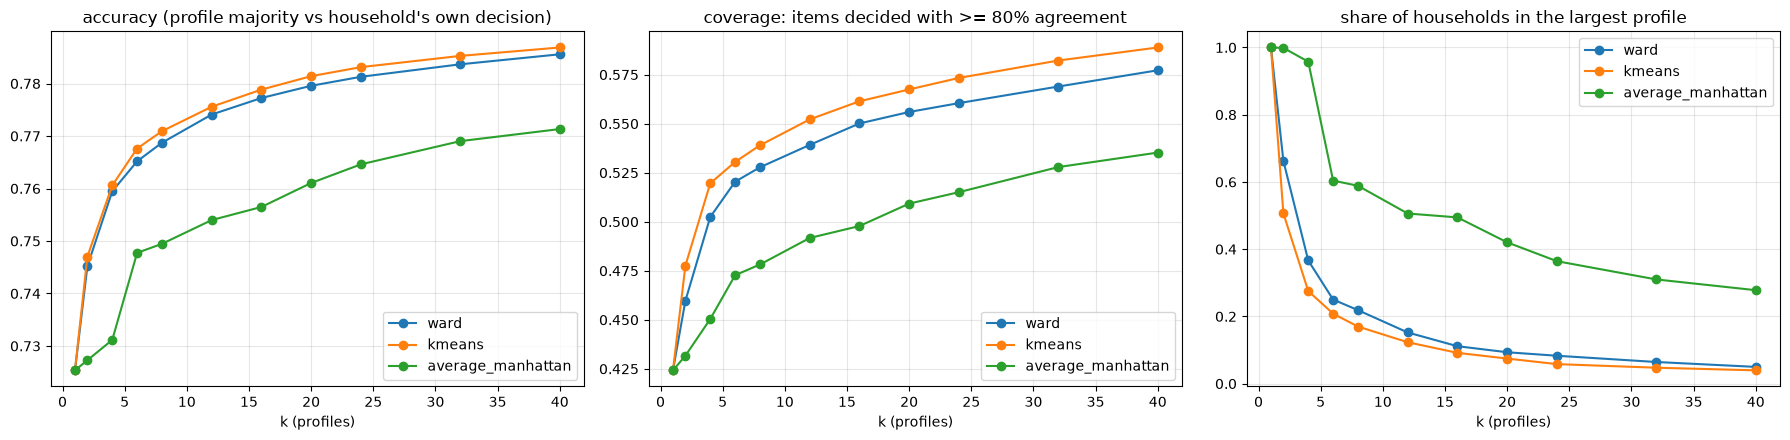

,acc_majority,acc_majority_plausible,acc_majority_real,coverage_80,acc_covered_80,largest_profile
k,,,,,,
1,0.725,0.753,0.839,0.424,0.935,1.000
2,0.745,0.771,0.850,0.460,0.944,0.662
4,0.759,0.786,0.866,0.502,0.942,0.366
6,0.765,0.792,0.872,0.520,0.943,0.250
8,0.769,0.795,0.874,0.528,0.944,0.219
12,0.774,0.800,0.877,0.539,0.946,0.152
16,0.777,0.803,0.878,0.550,0.945,0.111
20,0.780,0.805,0.879,0.556,0.946,0.093
24,0.781,0.806,0.880,0.560,0.946,0.083


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for method in METHODS:
    r = cv.loc[method]
    axes[0].plot(r.index, r.acc_majority, marker="o", label=method)
    axes[1].plot(r.index, r.coverage_80, marker="o", label=method)
    axes[2].plot(r.index, r.largest_profile, marker="o", label=method)
axes[0].set_title("accuracy (profile majority vs household's own decision)")
axes[1].set_title("coverage: items decided with >= 80% agreement")
axes[2].set_title("share of households in the largest profile")
for ax in axes: ax.set_xlabel("k (profiles)"); ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()
cv.loc["ward", ["acc_majority", "acc_majority_plausible", "acc_majority_real", "coverage_80", "acc_covered_80", "largest_profile"]].round(3)

### Agreement threshold (S20 tested 70/80/90%)

A higher threshold makes covered decisions more accurate but covers fewer items.

In [6]:
cv.loc["ward", [f"{w}_{t}" for t in ("70", "80", "90") for w in ("coverage", "acc_covered")]].round(3)

,coverage_70,acc_covered_70,coverage_80,acc_covered_80,coverage_90,acc_covered_90
k,,,,,,
1,0.541,0.895,0.424,0.935,0.296,0.971
2,0.574,0.907,0.460,0.944,0.330,0.976
4,0.615,0.908,0.502,0.942,0.370,0.973
6,0.630,0.909,0.520,0.943,0.390,0.973
8,0.635,0.912,0.528,0.944,0.400,0.973
12,0.644,0.914,0.539,0.946,0.414,0.974
16,0.654,0.914,0.550,0.945,0.426,0.973
20,0.659,0.915,0.556,0.946,0.431,0.973
24,0.662,0.916,0.560,0.946,0.437,0.973


### Fallbacks for items without agreement

S20 asked the user here; we may not. Overall accuracy when uncovered items are decided by each fallback (80%
threshold):

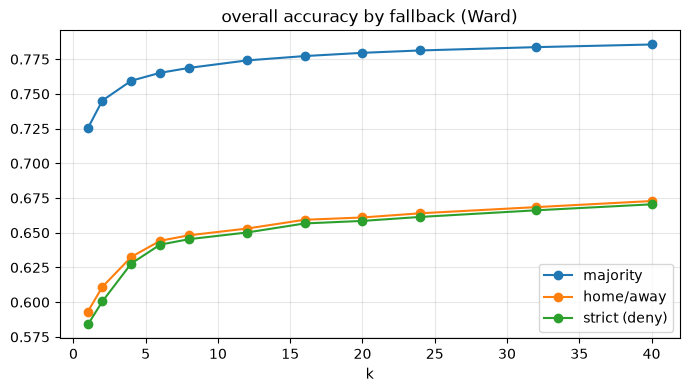

,majority,home/away,strict (deny)
k,,,
1,0.725,0.593,0.584
2,0.745,0.611,0.601
4,0.759,0.633,0.628
6,0.765,0.644,0.641
8,0.769,0.648,0.645
12,0.774,0.653,0.650
16,0.777,0.659,0.657
20,0.780,0.661,0.659
24,0.781,0.664,0.661


In [7]:
fallbacks = cv.loc["ward", ["acc_majority", "acc_home_away_80", "acc_strict_80"]].rename(
    columns={"acc_majority": "majority", "acc_home_away_80": "home/away", "acc_strict_80": "strict (deny)"})
ax = fallbacks.plot(marker="o", figsize=(8, 4), title="overall accuracy by fallback (Ward)"); ax.set_xlabel("k"); ax.grid(alpha=0.3)
plt.show()
fallbacks.round(3)

### Checks

In [8]:
w = cv.loc["ward"]
checks = {
    "profiles beat one preset for everyone (k=12 vs k=1)": w.loc[12, "acc_majority"] > w.loc[1, "acc_majority"] + 0.03,
    "covered decisions are accurate (>= 90% at 80% agreement)": (w.acc_covered_80 >= 0.9).all(),
    "coverage grows with k": w.coverage_80.loc[40] > w.coverage_80.loc[1],
    "real-device items are predicted better than the whole grid": (w.acc_majority_real > w.acc_majority).all(),
    "average linkage builds a dominant profile (as S20 observed)": cv.loc["average_manhattan"].loc[8, "largest_profile"] > 0.4,
}
assert all(checks.values()), checks
pd.Series(checks, name="holds")

profiles beat one preset for everyone (k=12 vs k=1)            True
covered decisions are accurate (>= 90% at 80% agreement)       True
coverage grows with k                                          True
real-device items are predicted better than the whole grid     True
average linkage builds a dominant profile (as S20 observed)    True
Name: holds, dtype: bool

### What this means

- Profiles beat one preset for everyone, with **diminishing returns**: most of the gain is reached by about k = 12–16.
  Choosing k is left to notebook 05, because more profiles also need more onboarding questions (S20: pick k by a
  budget of questions vs accuracy).
- Where a profile reaches 80% agreement its decision is right about 94% of the time, but that covers only about half
  of the items. The rest is each household's own item-by-item variation, which no profile can capture.
- Because we may not ask, the **fallback matters**: using the profile's majority keeps accuracy highest; the cautious
  *home/away* rule and *deny* contradict many households' own choices. Which fallback presets should use is a
  product/privacy decision for notebook 04 (accuracy vs caution), not only a statistic.
- The 52 real-device items are predicted better than the grid overall: they are common, less ambiguous flows.

## Profiles on all households

Ward clustering of all 5,000 households, cut at the candidate k values. Notebook 04 turns these into presets.

In [9]:
CANDIDATES = [4, 8, 12, 16, 20, 24]
labels_all = cluster("ward", C, CANDIDATES)
out = DATA / "profiles"; out.mkdir(exist_ok=True)
pd.DataFrame({"household_id": H.household_id, **{f"k{k}": labels_all[k] for k in CANDIDATES}}).to_csv(out / "labels_ward.csv", index=False)
for k in CANDIDATES:
    majority, agreement = build_profiles(D, labels_all[k], k)
    np.savez_compressed(out / f"profiles_ward_k{k}.npz", majority=majority, agreement=agreement.astype(np.float16),
                        size=np.bincount(labels_all[k], minlength=k), centroid=centroids(C, labels_all[k], k).astype(np.float32))
print("saved", sorted(p.name for p in out.iterdir()))

saved ['labels_ward.csv', 'profiles_ward_k12.npz', 'profiles_ward_k16.npz', 'profiles_ward_k20.npz', 'profiles_ward_k24.npz', 'profiles_ward_k4.npz', 'profiles_ward_k8.npz']


### What the profiles look like (k = 8)

Average acceptance (deny 0, allow-if 0.5, allow 1) of each profile per purpose, per recipient and per data type,
shown as the difference from all households. Red = stricter than average, blue = more accepting.

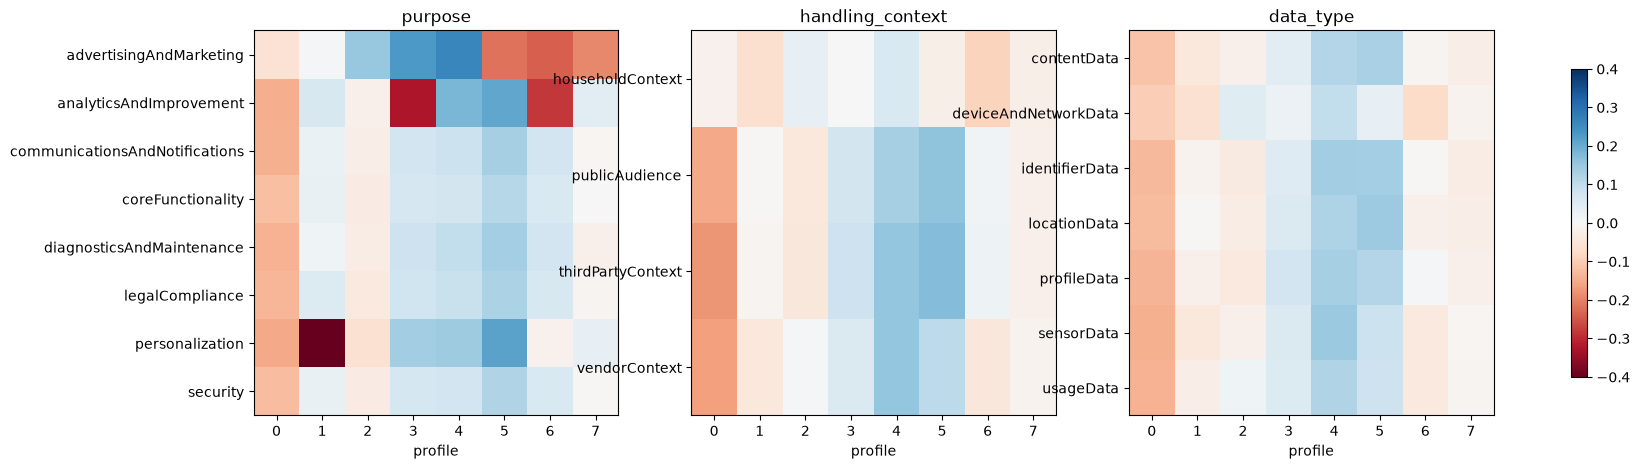

,households,acceptance,concern (avg),trust in maker (avg),ads attitude (avg),analytics attitude (avg)
0,1062,0.53,0.71,0.50,-0.53,-0.06
1,186,0.62,0.48,0.57,-0.47,0.20
2,732,0.64,0.57,0.61,-0.09,0.09
3,273,0.71,0.38,0.63,-0.06,-0.67
4,957,0.78,0.35,0.70,-0.03,0.35
5,405,0.76,0.26,0.67,-0.98,0.36
6,228,0.63,0.41,0.54,-1.01,-0.51
7,1157,0.63,0.52,0.59,-0.94,0.20


In [10]:
K = 8
lab = labels_all[K]
ordinal = np.array([0.0, 1.0, 0.5, 0.5, 0.5], dtype=np.float32)
V = ordinal[D]
overall = V.mean(axis=0)
def by(field):
    groups = items[field].map(short)
    prof = pd.DataFrame({c: pd.Series(V[lab == c].mean(axis=0)).groupby(groups).mean() for c in range(K)})
    return prof.sub(pd.Series(overall).groupby(groups).mean(), axis=0)
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
for ax, field in zip(axes, ["purpose", "handling_context", "data_type"]):
    t = by(field)
    im = ax.imshow(t.values, cmap="RdBu", vmin=-0.4, vmax=0.4, aspect="auto")
    ax.set_yticks(range(len(t))); ax.set_yticklabels(t.index); ax.set_xticks(range(K)); ax.set_xlabel("profile"); ax.set_title(field)
fig.colorbar(im, ax=axes, shrink=0.8); plt.show()
summary = pd.DataFrame({
    "households": np.bincount(lab, minlength=K),
    "acceptance": [V[lab == c].mean() for c in range(K)],
    "concern (avg)": [H.concern[lab == c].mean() for c in range(K)],
    "trust in maker (avg)": [H.vendor_trust[lab == c].mean() for c in range(K)],
    "ads attitude (avg)": [H.att_advertisingAndMarketing[lab == c].mean() for c in range(K)],
    "analytics attitude (avg)": [H.att_analyticsAndImprovement[lab == c].mean() for c in range(K)],
})
summary.round(2)

Profiles differ in **which** purposes, recipients and data types they accept, not only in overall strictness: the
v2 generator's goal. Naming them ("keeps video home", "fine with analytics, no ads", …) is part of notebook 04.